# Aircraft Family Recognition Using Deep Learning and Grad-CAM

**Task:** classify an aircraft photo into one of **70 aircraft families** (e.g. Boeing 737, Airbus A320, Cessna 172) using transfer learning, then explain predictions with **Grad-CAM**.

**Dataset:** FGVC-Aircraft (Maji et al., 2013), 10,000 images, official train / val / test split of 3,334 / 3,333 / 3,333, family-level labels. Released for non-commercial research and education.

**Pipeline:** data checks -> 3 pretrained CNNs fine-tuned (MobileNetV2, ResNet18, EfficientNet-B0) -> model selection on the **validation** set only -> one-time evaluation on the **test** set -> confusion analysis -> Grad-CAM gallery + deletion-based faithfulness check -> export weights / ONNX / metrics for GitHub + Vercel.

Runtime: Colab, GPU (T4). Run all cells top to bottom (about 25-40 minutes).

In [1]:
!pip -q install onnx onnxruntime
import os, json, time, random, zipfile, shutil, platform
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, f1_score

SEED = 42
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("device:", device, "| torch", torch.__version__, "| torchvision", torchvision.__version__)
if device.type != "cuda":
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU, then rerun.")

OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

device: cuda | torch 2.11.0+cu130 | torchvision 0.26.0+cu130


## 1. Dataset (official FGVC-Aircraft split, family level)

In [2]:
ROOT = "data"
class DropBanner:
    """FGVC-Aircraft images carry a 20 px copyright banner at the bottom; remove it so the model cannot read it."""
    def __init__(self, px=20): self.px = px
    def __call__(self, im):
        w, h = im.size
        return im.crop((0, 0, w, h - self.px))

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
norm = transforms.Normalize(MEAN, STD)

train_tf = transforms.Compose([
    DropBanner(), transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), norm])
eval_tf = transforms.Compose([DropBanner(), transforms.Resize((224, 224)), transforms.ToTensor(), norm])
vis_tf  = transforms.Compose([DropBanner(), transforms.Resize((224, 224)), transforms.ToTensor()])  # un-normalised, for plots

mk = lambda split, tf: datasets.FGVCAircraft(ROOT, split=split, annotation_level="family", transform=tf, download=True)
train_ds, val_ds, test_ds = mk("train", train_tf), mk("val", eval_tf), mk("test", eval_tf)
vis_test = mk("test", vis_tf)
classes = train_ds.classes
NUM_CLASSES = len(classes)
print("classes:", NUM_CLASSES, "| train/val/test:", len(train_ds), len(val_ds), len(test_ds))
print(classes[:10], "...")

BS = 64
train_loader = torch.utils.data.DataLoader(train_ds, BS, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader   = torch.utils.data.DataLoader(val_ds, BS, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = torch.utils.data.DataLoader(test_ds, BS, shuffle=False, num_workers=2, pin_memory=True)

100%|██████████| 2.75G/2.75G [01:49<00:00, 25.2MB/s]


classes: 70 | train/val/test: 3334 3333 3333
['A300', 'A310', 'A320', 'A330', 'A340', 'A380', 'ATR-42', 'ATR-72', 'An-12', 'BAE 146'] ...


train: min 33 / max 267 images per class
val: min 33 / max 266 images per class
test: min 33 / max 267 images per class


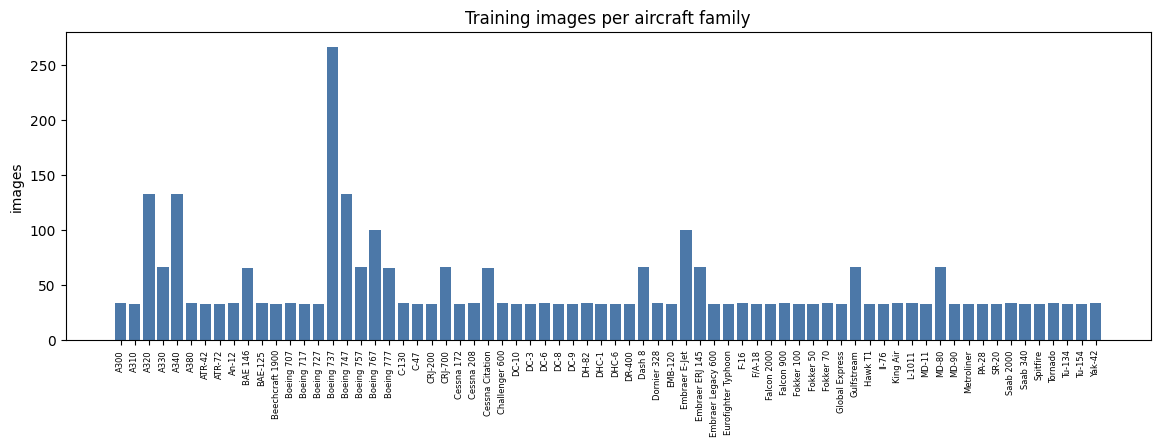

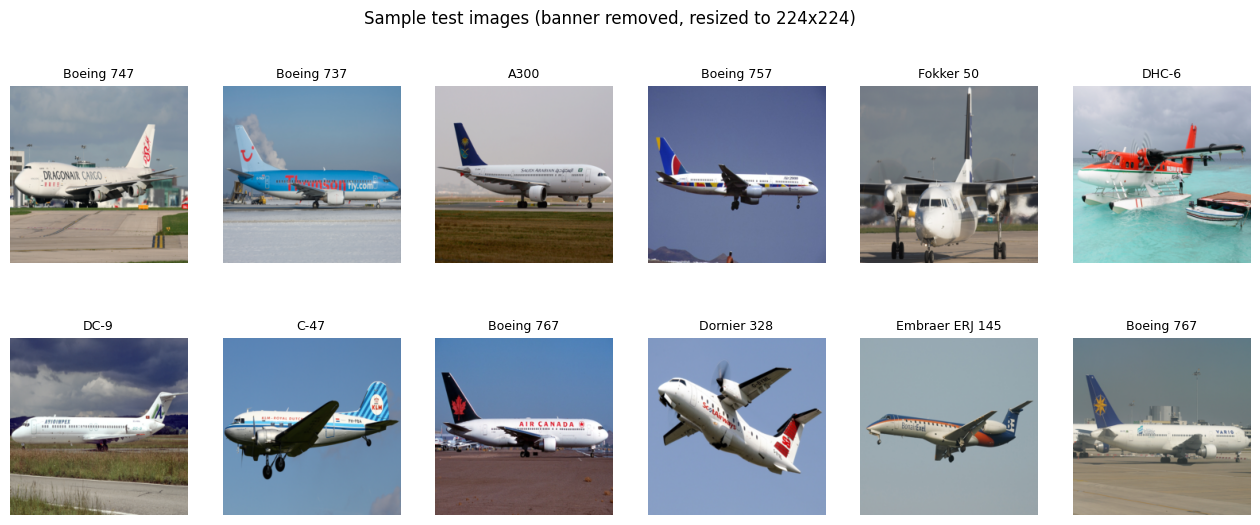

In [3]:
# Data exploration: class balance per split + sample images
counts = {n: np.bincount(d._labels, minlength=NUM_CLASSES) for n, d in [("train", train_ds), ("val", val_ds), ("test", test_ds)]}
for n, c in counts.items():
    print(f"{n}: min {c.min()} / max {c.max()} images per class")

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(NUM_CLASSES), counts["train"], color="#4c78a8")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(classes, rotation=90, fontsize=6)
ax.set_title("Training images per aircraft family"); ax.set_ylabel("images")
plt.savefig(f"{OUT}/class_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, i in zip(axes.ravel(), np.random.RandomState(0).choice(len(vis_test), 12, replace=False)):
    img, y = vis_test[i]
    ax.imshow(img.permute(1, 2, 0)); ax.set_title(classes[y], fontsize=9); ax.axis("off")
plt.suptitle("Sample test images (banner removed, resized to 224x224)")
plt.savefig(f"{OUT}/sample_images.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Models (ImageNet-pretrained, fine-tuned end to end)

In [4]:
def build(name):
    if name == "mobilenet_v2":
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.last_channel, NUM_CLASSES)
    elif name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
    return m

# last convolutional block, used as the Grad-CAM target
TARGET_LAYER = {
    "mobilenet_v2":    lambda m: m.features[-1],
    "resnet18":        lambda m: m.layer4[-1],
    "efficientnet_b0": lambda m: m.features[-1],
}
MODEL_NAMES = ["mobilenet_v2", "resnet18", "efficientnet_b0"]

EPOCHS, LR = 20, 5e-4
crit = nn.CrossEntropyLoss(label_smoothing=0.1)

def run_eval(model, loader):
    model.eval(); n = correct = 0; loss_sum = 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
            loss_sum += F.cross_entropy(out.float(), y, reduction="sum").item()
            correct += (out.argmax(1) == y).sum().item(); n += y.numel()
    return loss_sum / n, correct / n

def fit(name):
    seed_all(SEED)
    model = build(name).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(train_loader), pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state, t0 = -1.0, None, time.time()
    for ep in range(EPOCHS):
        model.train(); n = correct = 0; loss_sum = 0.0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            loss_sum += loss.item() * y.numel(); correct += (out.argmax(1) == y).sum().item(); n += y.numel()
        vl, va = run_eval(model, val_loader)
        hist["train_loss"].append(loss_sum / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if va > best_acc:
            best_acc = va; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"[{name}] epoch {ep+1:02d}/{EPOCHS}  train_acc {correct/n:.3f}  val_acc {va:.3f}  val_loss {vl:.3f}")
    model.load_state_dict(best_state)
    return model, hist, {"best_val_acc": best_acc, "train_seconds": time.time() - t0,
                         "params_millions": sum(p.numel() for p in model.parameters()) / 1e6}

## 3. Train all three models

In [5]:
trained, histories, summary = {}, {}, {}
for name in MODEL_NAMES:
    trained[name], histories[name], summary[name] = fit(name)
    print(name, summary[name], "\n")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 144MB/s]


[mobilenet_v2] epoch 01/20  train_acc 0.061  val_acc 0.126  val_loss 3.657
[mobilenet_v2] epoch 02/20  train_acc 0.266  val_acc 0.340  val_loss 2.513
[mobilenet_v2] epoch 03/20  train_acc 0.526  val_acc 0.455  val_loss 1.978
[mobilenet_v2] epoch 04/20  train_acc 0.695  val_acc 0.619  val_loss 1.485
[mobilenet_v2] epoch 05/20  train_acc 0.772  val_acc 0.629  val_loss 1.349
[mobilenet_v2] epoch 06/20  train_acc 0.844  val_acc 0.639  val_loss 1.335
[mobilenet_v2] epoch 07/20  train_acc 0.906  val_acc 0.694  val_loss 1.203
[mobilenet_v2] epoch 08/20  train_acc 0.943  val_acc 0.725  val_loss 1.134
[mobilenet_v2] epoch 09/20  train_acc 0.959  val_acc 0.706  val_loss 1.152
[mobilenet_v2] epoch 10/20  train_acc 0.980  val_acc 0.734  val_loss 1.152
[mobilenet_v2] epoch 11/20  train_acc 0.980  val_acc 0.742  val_loss 1.090
[mobilenet_v2] epoch 12/20  train_acc 0.983  val_acc 0.750  val_loss 1.089
[mobilenet_v2] epoch 13/20  train_acc 0.991  val_acc 0.754  val_loss 1.087
[mobilenet_v2] epoch 14/2

100%|██████████| 44.7M/44.7M [00:00<00:00, 187MB/s]


[resnet18] epoch 01/20  train_acc 0.073  val_acc 0.223  val_loss 3.412
[resnet18] epoch 02/20  train_acc 0.372  val_acc 0.390  val_loss 2.351
[resnet18] epoch 03/20  train_acc 0.609  val_acc 0.413  val_loss 2.207
[resnet18] epoch 04/20  train_acc 0.754  val_acc 0.492  val_loss 1.856
[resnet18] epoch 05/20  train_acc 0.840  val_acc 0.437  val_loss 2.151
[resnet18] epoch 06/20  train_acc 0.887  val_acc 0.507  val_loss 2.028
[resnet18] epoch 07/20  train_acc 0.938  val_acc 0.584  val_loss 1.600
[resnet18] epoch 08/20  train_acc 0.960  val_acc 0.662  val_loss 1.375
[resnet18] epoch 09/20  train_acc 0.976  val_acc 0.684  val_loss 1.333
[resnet18] epoch 10/20  train_acc 0.984  val_acc 0.710  val_loss 1.270
[resnet18] epoch 11/20  train_acc 0.987  val_acc 0.715  val_loss 1.272
[resnet18] epoch 12/20  train_acc 0.995  val_acc 0.744  val_loss 1.197
[resnet18] epoch 13/20  train_acc 0.997  val_acc 0.745  val_loss 1.198
[resnet18] epoch 14/20  train_acc 0.998  val_acc 0.755  val_loss 1.206
[resne

100%|██████████| 20.5M/20.5M [00:00<00:00, 163MB/s]


[efficientnet_b0] epoch 01/20  train_acc 0.042  val_acc 0.091  val_loss 3.986
[efficientnet_b0] epoch 02/20  train_acc 0.174  val_acc 0.295  val_loss 3.067
[efficientnet_b0] epoch 03/20  train_acc 0.455  val_acc 0.503  val_loss 1.882
[efficientnet_b0] epoch 04/20  train_acc 0.678  val_acc 0.623  val_loss 1.393
[efficientnet_b0] epoch 05/20  train_acc 0.820  val_acc 0.672  val_loss 1.240
[efficientnet_b0] epoch 06/20  train_acc 0.883  val_acc 0.687  val_loss 1.119
[efficientnet_b0] epoch 07/20  train_acc 0.923  val_acc 0.719  val_loss 1.046
[efficientnet_b0] epoch 08/20  train_acc 0.948  val_acc 0.745  val_loss 0.971
[efficientnet_b0] epoch 09/20  train_acc 0.968  val_acc 0.743  val_loss 0.983
[efficientnet_b0] epoch 10/20  train_acc 0.979  val_acc 0.765  val_loss 0.962
[efficientnet_b0] epoch 11/20  train_acc 0.985  val_acc 0.759  val_loss 0.969
[efficientnet_b0] epoch 12/20  train_acc 0.989  val_acc 0.761  val_loss 0.965
[efficientnet_b0] epoch 13/20  train_acc 0.990  val_acc 0.773  v

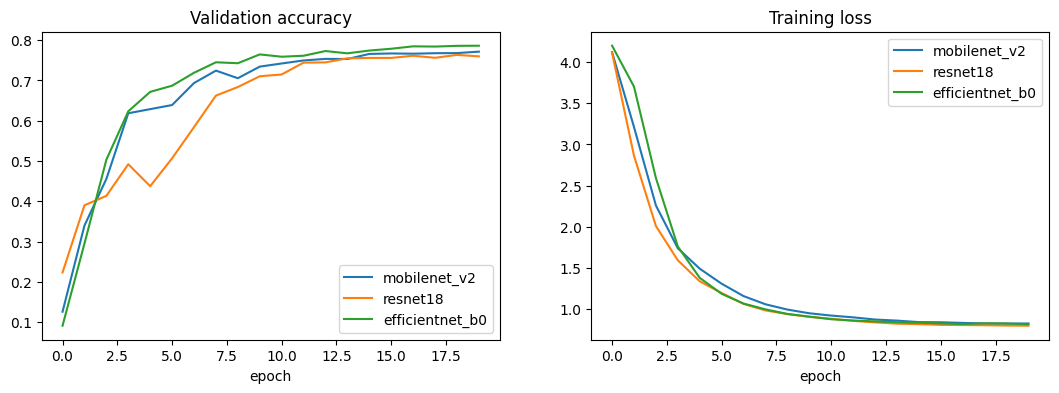

Selected model (by validation accuracy): efficientnet_b0


In [6]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in MODEL_NAMES:
    axes[0].plot(histories[name]["val_acc"], label=name)
    axes[1].plot(histories[name]["train_loss"], label=name)
axes[0].set_title("Validation accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].set_title("Training loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.savefig(f"{OUT}/training_curves.png", dpi=150, bbox_inches="tight"); plt.show()

# Model selection uses VALIDATION accuracy only (ties -> fewer parameters). The test set is not used for choosing.
best_name = sorted(MODEL_NAMES, key=lambda n: (-summary[n]["best_val_acc"], summary[n]["params_millions"]))[0]
print("Selected model (by validation accuracy):", best_name)

## 4. Test-set evaluation (run once, after selection)

model              val acc  test top1  test top5  macro F1  params(M)  train s
mobilenet_v2        0.7717     0.7804     0.9352    0.7642       2.31     1581
resnet18            0.7636     0.7702     0.9184    0.7516      11.21     1528
efficientnet_b0     0.7864     0.7996     0.9406    0.7821       4.10     1566


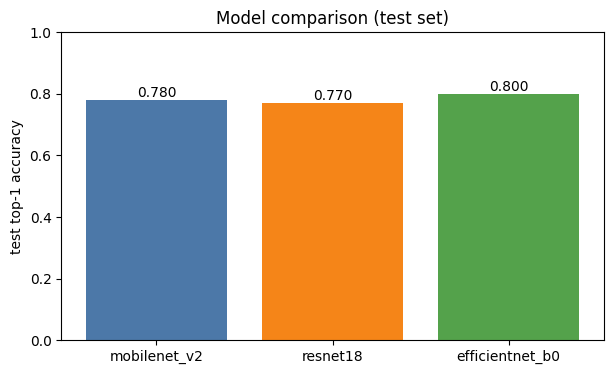

                     precision    recall  f1-score   support

               A300      0.650     0.394     0.491        33
               A310      0.667     0.667     0.667        33
               A320      0.852     0.776     0.812       134
               A330      0.595     0.712     0.648        66
               A340      0.807     0.903     0.852       134
               A380      0.923     0.727     0.814        33
             ATR-42      0.794     0.818     0.806        33
             ATR-72      0.733     0.647     0.688        34
              An-12      0.842     0.970     0.901        33
            BAE 146      0.941     0.955     0.948        67
            BAE-125      0.967     0.879     0.921        33
    Beechcraft 1900      0.763     0.879     0.817        33
         Boeing 707      0.600     0.455     0.517        33
         Boeing 717      0.690     0.588     0.635        34
         Boeing 727      0.692     0.545     0.610        33
         Boeing 737    

In [7]:
def predict_all(model, loader):
    model.eval(); logits, ys = [], []
    with torch.no_grad():
        for x, y in loader:
            logits.append(model(x.to(device)).float().cpu()); ys.append(y)
    return torch.cat(logits), torch.cat(ys)

test_results = {}
for name in MODEL_NAMES:
    lg, ys = predict_all(trained[name], test_loader)
    pred = lg.argmax(1)
    top5 = (lg.topk(5, 1).indices == ys[:, None]).any(1).float().mean().item()
    test_results[name] = {"test_top1": (pred == ys).float().mean().item(), "test_top5": top5,
                          "test_macro_f1": f1_score(ys, pred, average="macro")}
    test_results[name].update(summary[name])
    if name == best_name:
        best_logits, best_ys, best_pred = lg, ys, pred

print(f"{'model':<17}{'val acc':>9}{'test top1':>11}{'test top5':>11}{'macro F1':>10}{'params(M)':>11}{'train s':>9}")
for n, r in test_results.items():
    print(f"{n:<17}{r['best_val_acc']:>9.4f}{r['test_top1']:>11.4f}{r['test_top5']:>11.4f}{r['test_macro_f1']:>10.4f}{r['params_millions']:>11.2f}{r['train_seconds']:>9.0f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(MODEL_NAMES, [test_results[n]["test_top1"] for n in MODEL_NAMES], color=["#4c78a8", "#f58518", "#54a24b"])
ax.set_ylim(0, 1); ax.set_ylabel("test top-1 accuracy"); ax.set_title("Model comparison (test set)")
for i, n in enumerate(MODEL_NAMES): ax.text(i, test_results[n]["test_top1"] + 0.01, f"{test_results[n]['test_top1']:.3f}", ha="center")
plt.savefig(f"{OUT}/model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

report = classification_report(best_ys, best_pred, target_names=classes, digits=3, zero_division=0)
open(f"{OUT}/classification_report.txt", "w").write(report)
print(report)

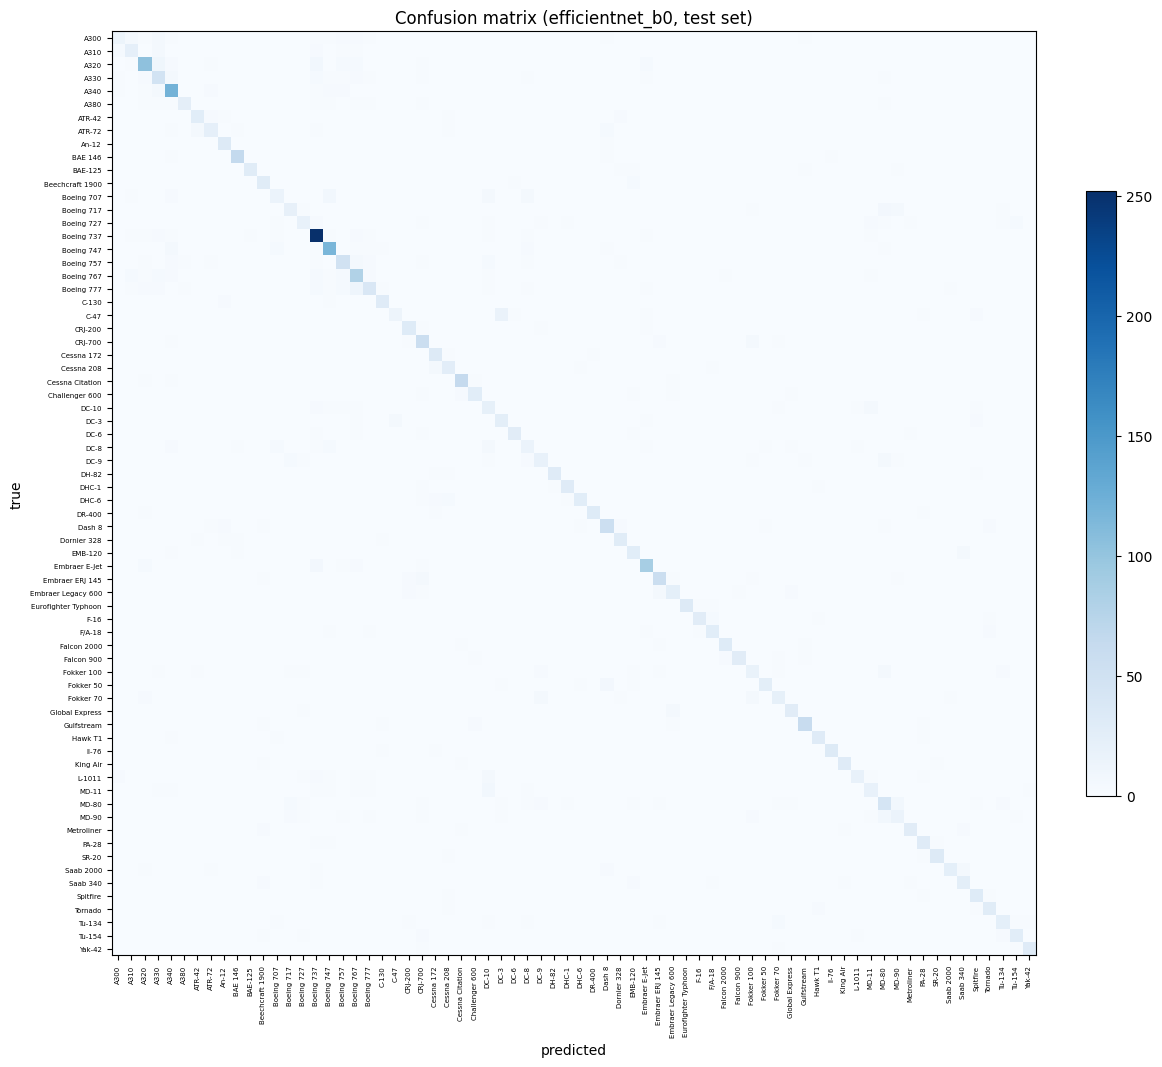

Most confused pairs (true -> predicted, count):
  C-47 -> DC-3: 16
  Boeing 777 -> Boeing 767: 11
  A320 -> A330: 9
  MD-90 -> MD-80: 7
  MD-80 -> MD-90: 7
  MD-11 -> DC-10: 7
  Boeing 707 -> Boeing 747: 7
  A320 -> Boeing 737: 7
  Fokker 50 -> Dash 8: 6
  Embraer E-Jet -> Boeing 737: 6

Weakest families: [('C-47', 0.36), ('A300', 0.39), ('DC-8', 0.45), ('Boeing 707', 0.45), ('MD-90', 0.45), ('Fokker 100', 0.52), ('Boeing 727', 0.55), ('MD-11', 0.55), ('DC-9', 0.56), ('Boeing 777', 0.57)]


In [8]:
# Confusion matrix + most confused family pairs + weakest classes
cm = confusion_matrix(best_ys, best_pred, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(13, 12))
im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im, fraction=0.03)
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(classes, rotation=90, fontsize=5); ax.set_yticklabels(classes, fontsize=5)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Confusion matrix ({best_name}, test set)")
plt.savefig(f"{OUT}/confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], classes[i], classes[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0], reverse=True)[:10]
print("Most confused pairs (true -> predicted, count):")
for c, t, p in pairs: print(f"  {t} -> {p}: {c}")

per_class = cm.diagonal() / cm.sum(1).clip(min=1)
worst = np.argsort(per_class)[:10]
print("\nWeakest families:", [(classes[i], round(float(per_class[i]), 2)) for i in worst])

## 5. Explainability: Grad-CAM

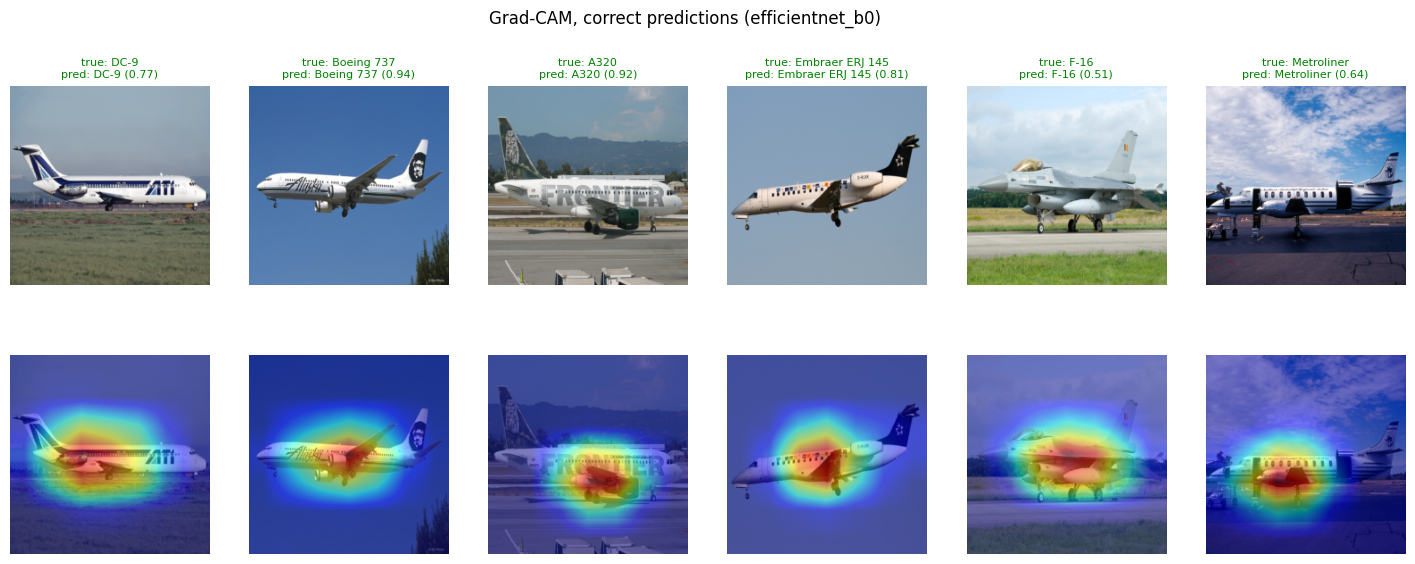

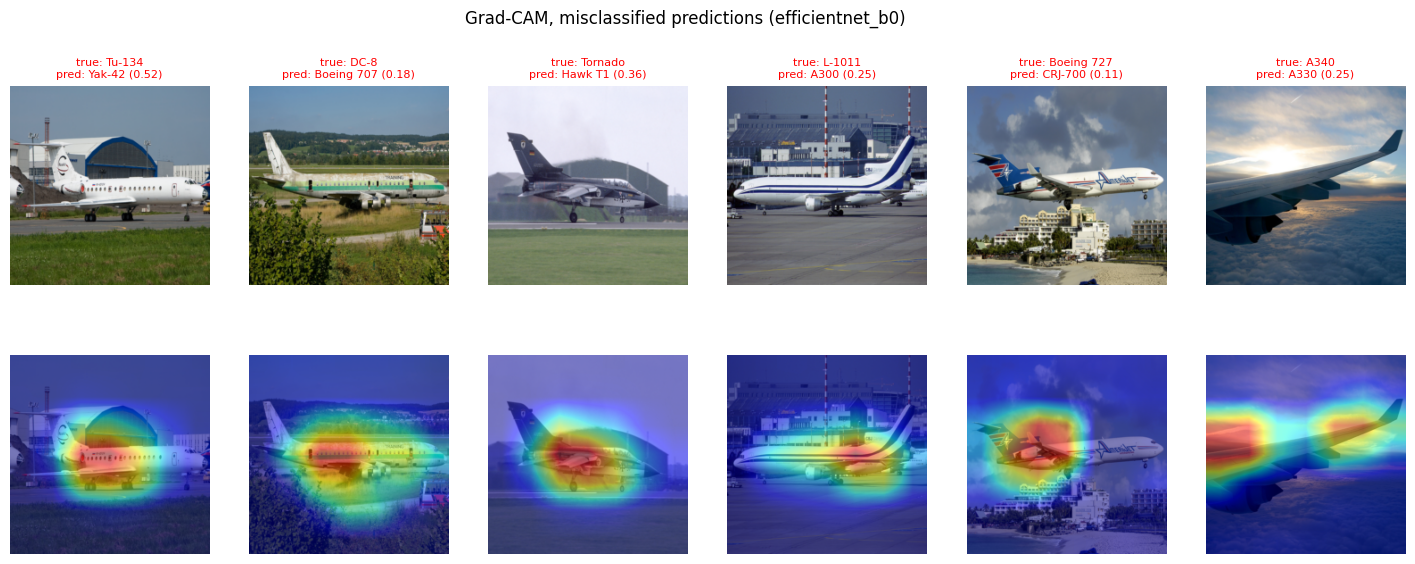

In [9]:
class GradCAM:
    """Grad-CAM (Selvaraju et al., 2017): weight the last conv feature maps by the spatial mean of the class-score gradient."""
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = layer.register_forward_hook(self._hook)
    def _hook(self, module, inp, out):
        self.acts = out.detach()
        if out.requires_grad:
            out.register_hook(lambda g: setattr(self, "grads", g.detach()))
    def __call__(self, x, class_idx=None):
        self.model.eval(); self.model.zero_grad(set_to_none=True)
        logits = self.model(x)
        if class_idx is None: class_idx = logits.argmax(1)
        logits.gather(1, class_idx.view(-1, 1)).sum().backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False).squeeze(1)
        flat = cam.flatten(1)
        mn, mx = flat.min(1)[0].view(-1, 1, 1), flat.max(1)[0].view(-1, 1, 1)
        return ((cam - mn) / (mx - mn + 1e-8)).detach().cpu(), logits.detach().cpu()
    def close(self): self.handle.remove()

best_model = trained[best_name].to(device).eval()
cam_engine = GradCAM(best_model, TARGET_LAYER[best_name](best_model))

def overlay(img, cam, alpha=0.5):
    heat = plt.cm.jet(cam.numpy())[..., :3]
    return np.clip((1 - alpha) * img.permute(1, 2, 0).numpy() + alpha * heat, 0, 1)

def cam_for(i, class_idx=None):
    img = vis_test[i][0]
    x = norm(img).unsqueeze(0).to(device)
    ci = None if class_idx is None else torch.tensor([class_idx], device=device)
    cam, logits = cam_engine(x, ci)
    return img, cam[0], logits[0].softmax(0)

rng = np.random.RandomState(1)
correct_idx = np.where(best_pred.numpy() == best_ys.numpy())[0]
wrong_idx = np.where(best_pred.numpy() != best_ys.numpy())[0]

def gallery(indices, title, fname):
    fig, axes = plt.subplots(2, len(indices), figsize=(3 * len(indices), 6.4))
    for k, i in enumerate(indices):
        img, cam, prob = cam_for(int(i))
        p = int(prob.argmax()); t = int(best_ys[i])
        axes[0, k].imshow(img.permute(1, 2, 0)); axes[0, k].axis("off")
        axes[0, k].set_title(f"true: {classes[t]}\npred: {classes[p]} ({prob[p]:.2f})", fontsize=8,
                             color="green" if p == t else "red")
        axes[1, k].imshow(overlay(img, cam)); axes[1, k].axis("off")
    plt.suptitle(title); plt.savefig(f"{OUT}/{fname}", dpi=150, bbox_inches="tight"); plt.show()

gallery(rng.choice(correct_idx, 6, replace=False), f"Grad-CAM, correct predictions ({best_name})", "gradcam_correct.png")
gallery(rng.choice(wrong_idx, 6, replace=False), f"Grad-CAM, misclassified predictions ({best_name})", "gradcam_errors.png")

{
  "images": 300,
  "mean_true_class_prob": 0.7708734565973282,
  "mean_drop_hiding_most_important_25pct": 0.737755088408788,
  "mean_drop_hiding_least_important_25pct": 0.006598421136538188,
  "fraction_images_where_top_region_hurts_more": 1.0
}


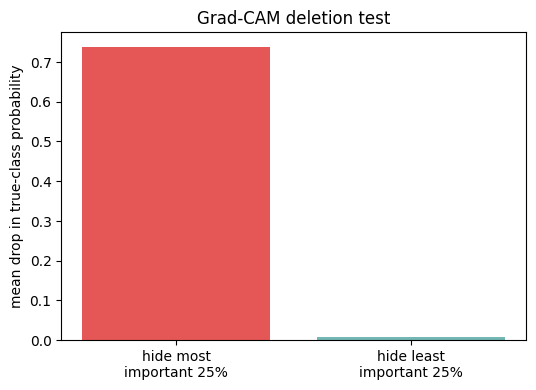

In [10]:
# Faithfulness sanity check (deletion test): if Grad-CAM is meaningful, hiding the MOST highlighted 25% of pixels
# should hurt the true-class probability more than hiding the LEAST highlighted 25%.
def deletion_test(n=300, frac=0.25, bs=30):
    idx = rng.choice(correct_idx, min(n, len(correct_idx)), replace=False)
    base, hi_drop, lo_drop = [], [], []
    for s in range(0, len(idx), bs):
        chunk = idx[s:s + bs]
        x = torch.stack([norm(vis_test[int(i)][0]) for i in chunk]).to(device)
        y = best_ys[chunk].to(device)
        cam, _ = cam_engine(x, y)
        flat = cam.flatten(1); k = int(frac * flat.shape[1]); order = flat.argsort(1)
        def masked(sel):
            m = torch.zeros_like(flat, dtype=torch.bool); m.scatter_(1, sel, True)
            return x.masked_fill(m.view(-1, 1, 224, 224).to(device), 0.0)   # 0.0 = dataset-mean colour after normalisation
        with torch.no_grad():
            p0 = best_model(x).softmax(1).gather(1, y[:, None]).squeeze(1)
            p_hi = best_model(masked(order[:, -k:])).softmax(1).gather(1, y[:, None]).squeeze(1)
            p_lo = best_model(masked(order[:, :k])).softmax(1).gather(1, y[:, None]).squeeze(1)
        base += p0.cpu().tolist(); hi_drop += (p0 - p_hi).cpu().tolist(); lo_drop += (p0 - p_lo).cpu().tolist()
    r = {"images": len(base), "mean_true_class_prob": float(np.mean(base)),
         "mean_drop_hiding_most_important_25pct": float(np.mean(hi_drop)),
         "mean_drop_hiding_least_important_25pct": float(np.mean(lo_drop)),
         "fraction_images_where_top_region_hurts_more": float(np.mean(np.array(hi_drop) > np.array(lo_drop)))}
    return r

deletion = deletion_test()
print(json.dumps(deletion, indent=2))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["hide most\nimportant 25%", "hide least\nimportant 25%"],
       [deletion["mean_drop_hiding_most_important_25pct"], deletion["mean_drop_hiding_least_important_25pct"]], color=["#e45756", "#72b7b2"])
ax.set_ylabel("mean drop in true-class probability"); ax.set_title("Grad-CAM deletion test")
plt.savefig(f"{OUT}/gradcam_deletion_test.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Export: weights, ONNX (for the Vercel demo), metrics, samples

In [11]:
cam_engine.close()
best_model = best_model.cpu().eval()

# 6.1 PyTorch weights
torch.save(best_model.state_dict(), f"{OUT}/aircraft_family_{best_name}.pth")

# 6.2 ONNX (runs in the browser with onnxruntime-web)
onnx_path = f"{OUT}/aircraft_family_{best_name}.onnx"
dummy = torch.randn(1, 3, 224, 224)
kw = dict(input_names=["input"], output_names=["logits"], dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17)
try:
    torch.onnx.export(best_model, dummy, onnx_path, dynamo=False, **kw)
except TypeError:
    torch.onnx.export(best_model, dummy, onnx_path, **kw)

# 6.3 verify ONNX == PyTorch on 100 test images
import onnxruntime as ort
sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
xs = torch.stack([test_ds[i][0] for i in range(100)])
with torch.no_grad(): torch_logits = best_model(xs).numpy()
onnx_logits = sess.run(None, {"input": xs.numpy()})[0]
onnx_agree = int((torch_logits.argmax(1) == onnx_logits.argmax(1)).sum())
max_diff = float(np.abs(torch_logits - onnx_logits).max())
print(f"ONNX agreement with PyTorch: {onnx_agree}/100 | max |logit diff| = {max_diff:.2e}")

# 6.4 labels + preprocessing contract (used by predict.py and the web app)
labels = {"classes": classes, "input_size": 224, "mean": MEAN, "std": STD, "layout": "NCHW", "resize": "stretch to 224x224 (no crop)"}
json.dump(labels, open(f"{OUT}/labels.json", "w"), indent=2)

# 6.5 sample images for the demo + the web gallery of Grad-CAM overlays
os.makedirs(f"{OUT}/samples", exist_ok=True); os.makedirs(f"{OUT}/gradcam_examples", exist_ok=True)
best_model_gpu = trained[best_name].to(device).eval()
cam_engine = GradCAM(best_model_gpu, TARGET_LAYER[best_name](best_model_gpu))
for k, i in enumerate(rng.choice(correct_idx, 12, replace=False)):
    img, cam, prob = cam_for(int(i))
    name = classes[int(best_ys[i])].replace(" ", "_").replace("/", "-")
    plt.imsave(f"{OUT}/samples/{k:02d}_{name}.jpg", img.permute(1, 2, 0).numpy())
    plt.imsave(f"{OUT}/gradcam_examples/{k:02d}_{name}_gradcam.png", overlay(img, cam))
cam_engine.close()

# 6.6 machine-readable results
results = {
    "project": "Aircraft Family Recognition Using Deep Learning and Grad-CAM",
    "dataset": {"name": "FGVC-Aircraft (2013b)", "annotation_level": "family", "num_classes": NUM_CLASSES,
                "split_sizes": {"train": len(train_ds), "val": len(val_ds), "test": len(test_ds)}, "split": "official"},
    "config": {"epochs": EPOCHS, "lr": LR, "batch_size": BS, "optimizer": "AdamW", "scheduler": "OneCycleLR",
               "label_smoothing": 0.1, "input_size": 224, "seed": SEED, "amp": use_amp, "banner_cropped_px": 20},
    "models": test_results, "selected_model": best_name, "selection_rule": "highest validation accuracy",
    "selected_test_top1": test_results[best_name]["test_top1"],
    "most_confused_pairs": [{"true": t, "pred": p, "count": int(c)} for c, t, p in pairs],
    "gradcam_deletion_test": deletion,
    "onnx_check": {"images": 100, "argmax_agreement": onnx_agree, "max_abs_logit_diff": max_diff},
    "environment": {"python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
                    "device": str(device), "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None},
}
json.dump(results, open(f"{OUT}/results.json", "w"), indent=2)

# 6.7 zip everything, back up to Drive (optional), download
shutil.make_archive("aircraft_outputs", "zip", OUT)
try:
    from google.colab import drive, files
    drive.mount("/content/drive")
    shutil.copytree(OUT, "/content/drive/MyDrive/aircraft_project", dirs_exist_ok=True)
    files.download("aircraft_outputs.zip")
except Exception as e:
    print("Drive/download step skipped:", e)
print(sorted(os.listdir(OUT)))

/tmp/ipykernel_702/429428242.py:12: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(best_model, dummy, onnx_path, dynamo=False, **kw)


ONNX agreement with PyTorch: 100/100 | max |logit diff| = 4.10e-05
Mounted at /content/drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

['aircraft_family_efficientnet_b0.onnx', 'aircraft_family_efficientnet_b0.pth', 'class_distribution.png', 'classification_report.txt', 'confusion_matrix.png', 'gradcam_correct.png', 'gradcam_deletion_test.png', 'gradcam_errors.png', 'gradcam_examples', 'labels.json', 'model_comparison.png', 'results.json', 'sample_images.png', 'samples', 'training_curves.png']
